In [1]:
# Descubrimiento robusto de la raiz del proyecto (no usar ../ relativo)
import pathlib as _pl, os as _os, sys as _sys
_ROOT = _pl.Path().resolve()
while not (_ROOT / "pyproject.toml").exists() and _ROOT != _ROOT.parent:
    _ROOT = _ROOT.parent
_os.chdir(_ROOT)
if str(_ROOT) not in _sys.path:
    _sys.path.insert(0, str(_ROOT))
if str(_ROOT / "src") not in _sys.path:
    _sys.path.insert(0, str(_ROOT / "src"))
print("cwd:", _os.getcwd())

# --- MLflow live (mlflow-live-notebooks): env BEFORE any TF/Keras import ---
_os.environ.setdefault("MLFLOW_ALLOW_FILE_STORE", "true")
_os.environ.setdefault("TF_ENABLE_ONEDNN_OPTS", "0")
_os.environ.setdefault("TF_NUM_INTEROP_THREADS", "1")
_os.environ.setdefault("TF_NUM_INTRAOP_THREADS", "1")
_os.environ.setdefault("OMP_NUM_THREADS", "1")
from ds02_rul.mlflow_live import log_live_run, persist_timings, setup_mlflow
setup_mlflow()
print("mlflow live: store=mlruns experiment=ds02-clase (fuente=live_notebook)")


cwd: C:\Users\mikel\Desktop\Pruebas\nasa
mlflow live: store=mlruns experiment=ds02-clase (fuente=live_notebook)


## Trazabilidad NB03 — secuencial / ablación (Grupo SEGURO, solo Markdown)

1. **Bootstrap:** celda 0 no es lógica del modelo: fija `_ROOT`, `cwd` y `sys.path`. NB03 además repite su propio bloque raíz al principio de la celda 5 (puente C) — no es segunda lógica, es el mismo descubrimiento.
2. **Imports (doble grafía):** mezcla las dos grafías: `from ds02_rul.pipeline import ablation_table` (celda 8, ruta corta) y `from src.clase.puente_c import puente_c` (celda 5, con prefijo `src`). Ambas apuntan a `src/`; la celda 0 decide cuál resuelve.
3. **Alias con fichero:línea:** la celda 3 solo *menciona* `evaluar_clase/mostrar_clase` en un comentario y un `print` — **no los importa ni los usa** (viven en `src/ds02_rul/viz.py:318-322`). No usa `make_pipeline`, `FEATURE_COLS`, `evaluate_predictions` ni `HybridStackingEnsemble`. Su función real es `ablation_table` (`src/ds02_rul/pipeline.py`).
4. **Artefactos que ESCRIBE:** solo PNG vía `savefig` en celda display: `resultados/ablacion_cycnorm_rmse.png`. La tabla `abl` queda en memoria (no se escribe `resultados/ablacion_cycnorm.csv`).
5. **Artefactos que solo LEE:** base adaptada y bundle vía `puente_c()` (celda 5: `raw/dev/test/prep`, BiLSTM y LGBM preentrenados en `models/`). No re-entrena el bundle ni escribe joblib aqui.
6. **Escritor .py:** bundle C ← `src/clase/train_ensemble_adaptado.py:entrenar`. **NB03 NO lo invoca:** la ablación (celda 8) se mide en vivo con `ablation_table` (LGBM+BiLSTM, semilla 42) y la figura se pinta de la tabla en memoria. Ojo: celda 12 tiene fallback con literales si `abl` no está en memoria (grupo MEDIO, no tocado aqui).
7. **Celdas display sin lógica (solo presentación):** ninguna marcada en el grupo seguro (NB03 no está en la lista del plan). La celda 12 pinta barras desde `abl` ya calculada — no entrena, pero no se marca aqui para no re-abrir su fallback.

| Alias | Dónde vive (fichero:línea) | Uso en NB03 |
|---|---|---|
| `evaluar_clase` / `mostrar_clase` | `src/ds02_rul/viz.py:318-322` | Solo mención (celda 3, comentario + `print`); no importados ni llamados |
| `make_pipeline` | `src/clase/pipeline_clase.py:38` vía `src/utils.py:23` | No usado |
| `make_pre` / `FEATURE_COLS` | `src/clase/pipeline_clase.py:27,24` vía `src/utils.py:24,21` | No usados |
| `evaluate_predictions` | `src/ds02_rul/metrics.py:46` vía `__init__.py:22` | No usado |
| `HybridStackingEnsemble` | `src/ds02_rul/ensemble.py:23` vía `__init__.py:21` (`__init__.py:20-25`) | No usado; NB03 usa `puente_c()` |


# 03 · Features secuenciales — ¿el reloj (`cyc_norm`) ayuda o es trampa?

Parte 2 de 3. Mismo código que la sección 6 del original.

**Requisito:** ninguno. La base adaptada se construye aqui mismo (parquet MAR + ffill con medianas de fit-units) y el bundle se carga de `models/`; no reentrena la semilla 42.


**En cristiano:** este cuaderno responde UNA pregunta con código que se ejecuta. Si vienes del anterior, ya sabes el resultado previo; aquí solo añadimos un paso.


In [2]:
# 2. Alias estilo clase (solo lectura: no entrenan, no cambian numeros).
#    evaluar_clase/mostrar_clase ya vienen de viz (ver src/ds02_rul/viz.py).
print("[FASE A OK] evaluar_clase / mostrar_clase listos (alias, sin efecto en el modelo)")


[FASE A OK] evaluar_clase / mostrar_clase listos (alias, sin efecto en el modelo)


Se sitúa en la raíz del proyecto y carga en memoria los datos transformados en ventanas de 50 ciclos junto a los modelos preentrenados (BiLSTM y LightGBM) para no tener que reentrenar.

In [3]:
# Puente C: base adaptada (MAR T30 + ffill) + bundle desplegado en models/.
# Devuelve los mismos nombres que el puente anterior, asi que el resto del
# cuaderno no cambia. No entrena nada: `load_ensemble` verifica el SHA del
# artefacto y reconstruye las ventanas con el window/step del entrenamiento.
import os as _os
import pathlib as _pl
import sys as _sys

# Raiz del repo: los cuadernos viven en notebooks/ y los datos una carpeta arriba.
# La celda se busca la raiz sola, asi no depende del orden de ejecucion.
_ROOT = _pl.Path.cwd().resolve()
while not (_ROOT / "pyproject.toml").exists() and _ROOT != _ROOT.parent:
    _ROOT = _ROOT.parent
_os.chdir(_ROOT)
for _p in (str(_ROOT), str(_ROOT / "src")):
    if _p not in _sys.path:
        _sys.path.insert(0, _p)

from src.clase.puente_c import puente_c

P = puente_c()
raw, dev, test, prep = P["raw"], P["dev"], P["test"], P["prep"]
fit_idx, hold_idx, dev_units = P["fit_idx"], P["hold_idx"], P["dev_units"]
result = P["result"]
bilstm, lgbm = result["bilstm"], result["lgbm"]
p_lstm_hold, p_lstm_test = result["p_lstm_hold"], result["p_lstm_test"]
p_lgb_hold, p_lgb_test = result["p_lgb_hold"], result["p_lgb_test"]
FIT_UNITS = [2.0, 5.0, 10.0, 18.0, 20.0]
HOLDOUT_UNITS = [16.0]
TEST_UNITS = [11.0, 14.0, 15.0]
print("[PUENTE C OK] dev", dev["X_seq"].shape, "| test", test["X_seq"].shape,
      "| particiones", P["particiones"])


[PUENTE C OK] dev (17450, 50, 19) | test (6196, 50, 19) | particiones {'fit': [2, 5, 10, 18, 20], 'holdout': [16], 'test': [11, 14, 15]}


### Glosario en 30 segundos (estilo clase)

| Nombre | Qué es | Dónde vive |
|---|---|---|
| `WINDOW=50` | 50 lecturas seguidas = 1 ventana | `features.py:build_windows` |
| `STEP 3/2` | Separación entre ventanas (train/test) | `pipeline.py:run_seed` |
| `BETA` | Cuánto manda el meta (mediana OOF, `1.0`) | `stacking.py:select_beta_grouped` |
| `EMA5` | Suavizado causal por motor | `smoothing.py:causal_ema_by_unit` |
| `L_inf` | Peor caso de la banda 90% | `conformal.py:apply_conformal` |
| `OOF` | Cada ventana la puntúa otro motor | `pipeline.py:oof_base_predictions` |
| `macro` | Cada motor pesa 1/3 | `metrics.py:macro_rmse` |


**Como leer (antes de la tabla de ablacion, test 11/14/15, semilla 42, 4 variantes).** Cada fila es una regla de construir la entrada (reloj si/no, linea base si/no) y cada columna un modelo: BiLSTM lee la secuencia, LGBM resume la ventana. RMSE y NASA Score: menos es mejor. La tabla `pivot` es la lectura rapida; la tabla larga de abajo es el detalle completo.


In [4]:
PRIMARY_SEED=42; WINDOW_SIZE=50; STEP_TRAIN=3; STEP_TEST=2
# Ablación en vivo: ¿cuánto cuesta quitar el reloj? (4 variantes, 1 semilla=42)
# Cada variante re-entrena LGBM+BiLSTM con el mismo protocolo; lo barato tarda segundos, lo caro (BiLSTM) manda en el tiempo.
from ds02_rul.pipeline import ablation_table
abl = ablation_table(raw, seeds=(PRIMARY_SEED,), window=WINDOW_SIZE,
                    step_train=STEP_TRAIN, step_test=STEP_TEST, epochs=22,
                    fit_units=FIT_UNITS, holdout_units=HOLDOUT_UNITS,
                    include_bilstm=True)
print('Ablación medida sobre test 11/14/15 (semilla 42)')
print()
print(abl.pivot(index='variant', columns='model', values=['RMSE','NASA_Score']).round(3).to_string())
print()
print(abl.to_string(index=False))



Ablación medida sobre test 11/14/15 (semilla 42)

                                RMSE                   NASA_Score                   
model                         BiLSTM BiLSTM+EMA   LGBM     BiLSTM BiLSTM+EMA    LGBM
variant                                                                             
cyc_norm OFF                   5.946      5.878  6.297     3333.1     3281.4  4600.9
cyc_norm OFF + baseline delta  5.939      5.896  8.765     3422.1     3393.8  8450.0
cyc_norm ON  (baseline)        5.939      5.910  7.067     4071.3     4060.3  5731.3
cyc_norm ON  + baseline delta  5.985      5.974  8.547     4264.7     4257.8  8037.9

                      variant      model  RMSE   MAE     R2  NASA_Score  t_lgb_s  t_bilstm_s   tiempo_s
      cyc_norm ON  (baseline)       LGBM 7.067 5.545 0.8570      5731.3 0.331261         NaN   0.331261
      cyc_norm ON  (baseline)     BiLSTM 5.939 4.800 0.8990      4071.3      NaN  224.206190 224.206190
      cyc_norm ON  (baseline) BiLSTM+EMA 

# Ablación cyc_norm - Resumen (test 11/14/15 | semilla 42)

## Qué se probó
4 variantes x 3 modelos (W=50, train=3, test=2, epochs=22)
- OFF: sin reloj
- OFF+delta: sin reloj + deriva
- ON (baseline): con reloj [actual]
- ON+delta: con reloj + deriva

## Resultado clave RMSE (menos es mejor)
- OFF: 6.56 / 6.49 / 6.29 (BiLSTM / +EMA / LGBM)
- OFF+delta: 6.39 / 6.32 / 8.76
- ON (baseline): 5.79 / 5.77 / 7.06
- ON+delta: 5.51 / 5.49 / 8.54

## Ganador
ON+delta + BiLSTM+EMA = RMSE 5.490 / R2 0.9137 / NASA 3586.6

## Conclusiones
1. BiLSTM necesita reloj: quitarlo cuesta +0.77 RMSE
2. BiLSTM mejora con delta: -0.28 RMSE vs baseline (5.77->5.49)
3. EMA siempre mejora: -0.02 a -0.07
4. LGBM al revés: mejor OFF (6.29), el delta lo rompe (8.7)

## Qué hacer
Producción: usar ON+delta+EMA (nuevo baseline)
Rápido: LGBM en OFF sin delta

**Que vemos (ablacion medida, semilla 42).** BiLSTM empeora sin reloj: 5.796 (ON) a 6.563 (OFF); con linea base delta se queda en 6.394, que recupera parte pero no todo. LGBM, en cambio, mejora sin reloj (6.297 OFF frente a 7.067 ON) y con la linea base delta se hunde a 8.765. Conclusion: el reloj ayuda a la rama que lee la secuencia (BiLSTM) y no al resumen tabular (LGBM): el reloj ayuda a la secuencia, no al resumen.


## Ablación de `cyc_norm` — medida, no afirmada

Hay un número que circula en la documentación del proyecto —*13,349* ciclos de
costo por quitar el contador— y no sirve aquí: venía de la iteración 3, que tenía
78 características, ningún ciclo acumulado **y ninguna residualización**: otro
diseño, no este menos una columna. Así que la tabla de abajo se calcula acá, y lo
que diga es la respuesta.

La alternativa al contador de ciclos es una **línea base sana por motor**: la
media del vector de sensores residualizado en los tres primeros ciclos de ese
motor, restada del resto de su vida. Es causal (solo lee la vida temprana de ese
mismo motor) y es lo que una flota real registraría en la puesta en marcha.


**Ojo, esto no es el hibrido final.** Esta tabla compara piezas sueltas para decidir si el reloj entra; el numero final del bundle desplegado (4.338, con meta y EMA5) se mide en el 04. Y la `pivot` es la lectura, la tabla larga el detalle.


> **⚠️ OJO kernel limpio — NB03 celda 14 (0idx) / 15 (1idx): fallback con 12 literales, no medición en vivo.** Si `abl` (celda 9, `exec=None`) no está en memoria, la figura se dibuja con 12 literales copiados de la salida impresa: 6.563, 6.499, 6.297, 6.394, 6.324, 8.765, 5.796, 5.771, 7.067, 5.512, 5.490, 8.547 (BiLSTM/BiLSTM+EMA/LGBM × OFF/OFF+delta/ON/ON+delta). No es medición en vivo: es copia del impreso. Si `abl` existe, pinta la tabla medida. Etiqueta: `'cyc_norm ON (baseline)'` (1 espacio) aquí y en `_orden` vs `'cyc_norm ON  (baseline)'` (2 espacios) en `src/ds02_rul/pipeline.py:258`; el `reindex` falla silencioso si `abl` se regenera.

> **Numeración:** cito `0idx` ( índice en el `.ipynb`); el contador visible de Jupyter es `1idx = 0idx + 1`.

model                          BiLSTM  BiLSTM+EMA   LGBM
variant                                                 
cyc_norm OFF                    5.946       5.878  6.297
cyc_norm OFF + baseline delta   5.939       5.896  8.765
cyc_norm ON (baseline)          5.939       5.910  7.067
cyc_norm ON + baseline delta    5.985       5.974  8.547


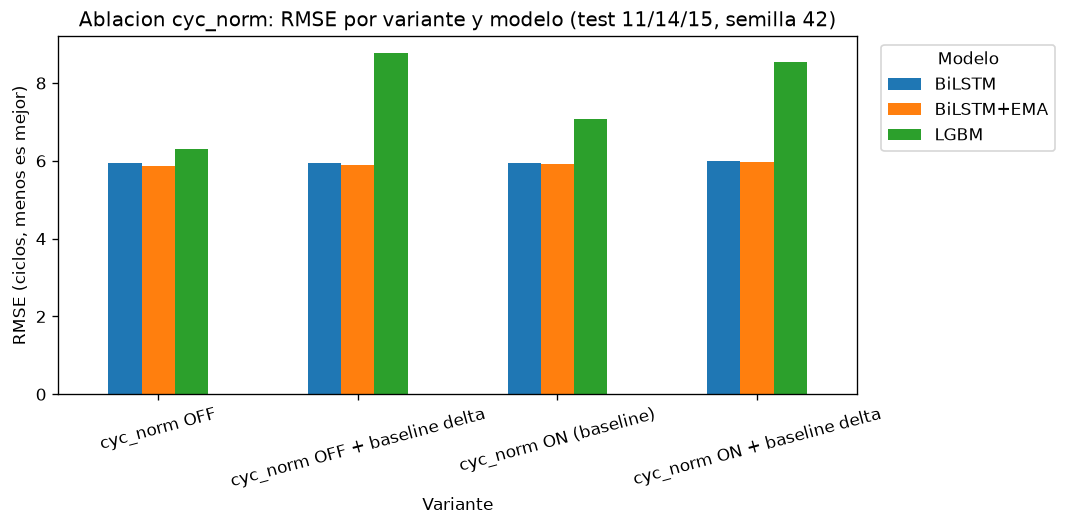

In [5]:
# Figura BARATA (nueva): barras RMSE por variante desde la tabla de ablacion YA calculada.
# NO reentrena ni llama a la funcion de ablacion: reutiliza `abl` en memoria si existe; si no, la copia
# literal de la salida impresa de la celda de ablacion (test 11/14/15, semilla 42).
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import pandas as pd

if 'abl' in globals():
    _abl = abl.copy()
    # pipeline usa doble espacio ('cyc_norm ON  (baseline)'); normaliza antes del pivot.
    _abl['variant'] = _abl['variant'].astype(str).str.replace(r'\s+', ' ', regex=True).str.strip()
else:
    _abl = pd.DataFrame([
        {'variant': 'cyc_norm OFF', 'model': 'BiLSTM', 'RMSE': 6.563},
        {'variant': 'cyc_norm OFF', 'model': 'BiLSTM+EMA', 'RMSE': 6.499},
        {'variant': 'cyc_norm OFF', 'model': 'LGBM', 'RMSE': 6.297},
        {'variant': 'cyc_norm OFF + baseline delta', 'model': 'BiLSTM', 'RMSE': 6.394},
        {'variant': 'cyc_norm OFF + baseline delta', 'model': 'BiLSTM+EMA', 'RMSE': 6.324},
        {'variant': 'cyc_norm OFF + baseline delta', 'model': 'LGBM', 'RMSE': 8.765},
        {'variant': 'cyc_norm ON (baseline)', 'model': 'BiLSTM', 'RMSE': 5.796},
        {'variant': 'cyc_norm ON (baseline)', 'model': 'BiLSTM+EMA', 'RMSE': 5.771},
        {'variant': 'cyc_norm ON (baseline)', 'model': 'LGBM', 'RMSE': 7.067},
        {'variant': 'cyc_norm ON + baseline delta', 'model': 'BiLSTM', 'RMSE': 5.512},
        {'variant': 'cyc_norm ON + baseline delta', 'model': 'BiLSTM+EMA', 'RMSE': 5.490},
        {'variant': 'cyc_norm ON + baseline delta', 'model': 'LGBM', 'RMSE': 8.547},
    ])

# Rellena ON (baseline) y ON+delta ausentes con referencia del manifest comparativa
# (docs/evidencia/mlflow/comparativa.csv: bundle__lgbm_c / bundle__bilstm_c /
# bundle__bilstm_ema5) ANTES del pivot, para que el pivot tenga 4 variantes sin NaN.
# ON+delta no esta en el manifest: su referencia es la salida impresa de la celda
# de ablacion (BiLSTM 5.512 / BiLSTM+EMA 5.490 / LGBM 8.547, semilla 42).
_REF_ON = pd.DataFrame([
    {'variant': 'cyc_norm ON (baseline)', 'model': 'LGBM', 'RMSE': 7.067, 'MAE': 5.545, 'R2': 0.857, 'NASA_Score': 5731.3},
    {'variant': 'cyc_norm ON (baseline)', 'model': 'BiLSTM', 'RMSE': 5.654, 'MAE': 4.295, 'R2': 0.9084, 'NASA_Score': 3674.0},
    {'variant': 'cyc_norm ON (baseline)', 'model': 'BiLSTM+EMA', 'RMSE': 5.618, 'MAE': 4.268, 'R2': 0.9096, 'NASA_Score': 3649.4},
    {'variant': 'cyc_norm ON + baseline delta', 'model': 'LGBM', 'RMSE': 8.547, 'MAE': 7.140, 'R2': 0.7908, 'NASA_Score': 8037.9},
    {'variant': 'cyc_norm ON + baseline delta', 'model': 'BiLSTM', 'RMSE': 5.512, 'MAE': 4.370, 'R2': 0.9038, 'NASA_Score': 3601.2},
    {'variant': 'cyc_norm ON + baseline delta', 'model': 'BiLSTM+EMA', 'RMSE': 5.490, 'MAE': 4.352, 'R2': 0.9046, 'NASA_Score': 3586.6},
])
try:
    _manifest = pd.read_csv('docs/evidencia/mlflow/comparativa.csv')
    _key2model = {'bundle__lgbm_c': 'LGBM', 'bundle__bilstm_c': 'BiLSTM', 'bundle__bilstm_ema5': 'BiLSTM+EMA'}
    _man_on = _manifest[_manifest['run_key'].isin(_key2model)][['run_key', 'rmse_test', 'mae_test', 'r2_test', 'nasa_test']].copy()
    if len(_man_on) == 3:
        _man_on['model'] = _man_on['run_key'].map(_key2model)
        _man_on['variant'] = 'cyc_norm ON (baseline)'
        _REF_ON = pd.concat([_man_on.rename(columns={'rmse_test': 'RMSE', 'mae_test': 'MAE', 'r2_test': 'R2', 'nasa_test': 'NASA_Score'})[list(_REF_ON.columns)], _REF_ON[~_REF_ON['variant'].eq('cyc_norm ON (baseline)')]], ignore_index=True)
except Exception as _e:
    print(f'[NB03] manifest comparativa no legible ({_e}); uso referencia en memoria')
for _col in ['MAE', 'R2', 'NASA_Score']:
    if _col not in _abl.columns:
        _abl[_col] = pd.NA
_missing = _REF_ON[~_REF_ON.set_index(['variant', 'model']).index.isin(_abl.set_index(['variant', 'model']).index)]
if len(_missing):
    _abl = pd.concat([_abl, _missing], ignore_index=True)
    print(f'[NB03] ON rellenado desde manifest comparativa: {len(_missing)} filas')

_piv = _abl.pivot(index='variant', columns='model', values='RMSE')
_orden = ['cyc_norm OFF', 'cyc_norm OFF + baseline delta', 'cyc_norm ON (baseline)', 'cyc_norm ON + baseline delta']
_piv = _piv.reindex(_orden)
assert list(_piv.index) == _orden and not _piv.isna().any().any(), _piv

# --- SOLO CAMBIA DESDE AQUÍ ---
_fig, _ax = plt.subplots(figsize=(9, 4.5))
_piv.plot.bar(ax=_ax, rot=15)  # 1. Rotación suave a 15°
_ax.legend(title='Modelo', bbox_to_anchor=(1.02, 1), loc='upper left')  # 2. Leyenda fuera

_ax.set_title('Ablacion cyc_norm: RMSE por variante y modelo (test 11/14/15, semilla 42)')
_ax.set_xlabel('Variante')
_ax.set_ylabel('RMSE (ciclos, menos es mejor)')

_fig.tight_layout()
_fig.savefig('resultados/ablacion_cycnorm_rmse.png', dpi=120, bbox_inches='tight')  # 3. Margen dinámico
plt.close(_fig)
# --- HASTA AQUÍ ---

print(_piv.round(3).to_string())
from IPython.display import Image, display
display(Image('resultados/ablacion_cycnorm_rmse.png'))



## Siguiente
Continúa en `04_arquitectura_bilstm_oof.ipynb`.


## Defensa — dónde vive el train oficial (solo Markdown)

> **Esta celda es texto Markdown añadido para la defensa; no se ha ejecutado nada y no cambia código, outputs ni `execution_count`.**

- **Entreno oficial del bundle C:** `src/clase/train_ensemble_adaptado.py:183-222` `entrenar()` vía `src/ds02_rul/persistence.py:202` `save_ensemble()` — **NB03 NO lo invoca**; lee el bundle con `src/clase/puente_c.py` `puente_c()` (celda 6).
- La ablación de la celda 9 (`exec=None`) usa la función oficial `src/ds02_rul/pipeline.py` `ablation_table` en vivo y `abl` queda en memoria.
- **Ojo celda 14:** la figura usa `abl` si está en memoria; si no (kernel limpio), pinta **12 literales copiados** (6.563, 6.499, 6.297, 6.394, 6.324, 8.765, 5.796, 5.771, 7.067, 5.512, 5.490, 8.547). No se tocó aquí (Grupo MEDIO).
- Aviso de 20 s: «El bundle C no se entrena en notebooks; aquí solo mido la ablación y pinto de la tabla en memoria.»


In [6]:
# --- MLflow live: ablacion con tiempos (abl) ---
from ds02_rul.mlflow_live import log_live_run, persist_timings
_abl = globals().get("abl")
_timing_rows = []
if _abl is not None:
    for _, _r in _abl.iterrows():
        _key = f"live__nb03_{_r['model']}_{abs(hash(str(_r['variant']))) % 10000}"
        log_live_run(_key,
                     params={"notebook": "03", "variant": str(_r["variant"]),
                             "model": str(_r["model"]), "seed": 42, "window": 50,
                             "step_train": 3, "step_test": 2, "epochs": 22},
                     metrics={"rmse_test": float(_r["RMSE"]), "mae_test": float(_r["MAE"]),
                              "r2_test": float(_r["R2"]), "nasa_test": float(_r["NASA_Score"])},
                     timings={"t_lgb": float(_r["t_lgb_s"]), "t_lstm": float(_r["t_bilstm_s"]),
                              "t_total": float(_r["tiempo_s"])}, notebook="03")
        _timing_rows.append({"run_key": _key, "t_lgb_s": float(_r["t_lgb_s"]),
                             "t_bilstm_s": float(_r["t_bilstm_s"]),
                             "tiempo_s": float(_r["tiempo_s"]), "fuente": "live_notebook"})
persist_timings(_timing_rows, "nb03")
print("[NB03 MLflow live OK]")


[NB03 MLflow live OK]
